# Análisis de Compras — Plataforma de E-Commerce en México

**Regression Analysis · Data Science Engineering · ITESO**

---

**Equipo:** Lambda Remiel Heredia Pérez · Octavio Pérez

**Dataset:** `plataforma_ecommerce_mx.csv`


---
# 1. Descripción de la empresa y las variables

## Contexto de negocio

Nos contrató una plataforma mexicana de e-commerce que vende en cuatro categorías de producto
(ropa, electrónica, hogar y deportes). Los clientes llegan por distintos canales (búsqueda, redes
sociales, campañas de correo, o de forma directa), navegan un rato, y algunos terminan comprando.
La empresa tiene un registro por compra: los datos demográficos del cliente, cómo navegó, cómo
llegó al sitio, y cuánto gastó.

Dos equipos necesitan este análisis:

- **Operaciones** quiere saber qué factores realmente determinan cuánto gasta un cliente por
  transacción, para planear inventario, personal y proyecciones de ingresos con base en eso.
- **Marketing** quiere saber si las diferencias de gasto promedio que observan entre regiones,
  géneros, dispositivos y fuentes de tráfico son patrones *reales* que vale la pena atender, o solo
  variación aleatoria en una muestra de 280 clientes.

Respondemos ambas preguntas con el mismo dataset usando dos métodos complementarios: **regresión
lineal múltiple** (qué factores predicen el gasto, y cuánto) y **ANOVA** (si las diferencias entre
medias de grupo son estadísticamente reales).

## Variables

| Variable | Tipo | Descripción |
|---|---|---|
| `id_cliente` | ID | Identificador único del cliente. No se usa como predictor. |
| `edad` | Continua (años enteros) | Edad del cliente. |
| `tiempo_navegacion_min` | Continua (minutos) | Tiempo de navegación en la sesión. |
| `visitas_previas` | Conteo discreto | Número de visitas previas antes de esta. |
| `gasto_historico_promedio_mxn` | Continua (MXN) | Gasto histórico promedio del cliente. |
| `genero` | Categórica nominal, 2 niveles | Femenino / Masculino. |
| `region` | Categórica nominal, 4 niveles | Centro / Norte / Sur / Occidente. |
| `dispositivo` | Categórica nominal, 3 niveles | Desktop / Móvil / Tablet. |
| `fuente_trafico` | Categórica nominal, 4 niveles | Búsqueda / Red Social / Email / Directo. |
| `categoria_interes` | Categórica nominal, 4 niveles | Ropa / Electrónica / Hogar / Deportes. |
| **`monto_compra_mxn`** | **Continua (MXN)** | **Monto de la compra — la variable dependiente.** |

`monto_compra_mxn` es lo que ambos métodos intentan explicar: la regresión la trata como una
respuesta continua determinada por una mezcla de predictores continuos y categóricos, y el ANOVA la
trata como una respuesta cuya media comparamos entre los niveles de los factores categóricos.


---
# 2. Limpieza y exploración de datos

## 2.1 Limpieza de datos


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_breusch_godfrey, linear_reset
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

TEAL, CORAL, GREY, GOLD = "#0F7173", "#D9622B", "#5C6B70", "#C9A227"
PALETTE = [TEAL, CORAL, GOLD, GREY]

In [2]:
df = pd.read_csv("plataforma_ecommerce_mx.csv", encoding="utf-8")
print(f"Filas: {df.shape[0]:,}   Columnas: {df.shape[1]}")
df.head()

Filas: 280   Columnas: 11


,id_cliente,edad,tiempo_navegacion_min,visitas_previas,gasto_historico_promedio_mxn,genero,region,dispositivo,fuente_trafico,categoria_interes,monto_compra_mxn
0,1,41,22,2,259,Femenino,Norte,Móvil,Email,Electrónica,1597
1,2,33,6,3,3667,Masculino,Centro,Tablet,Email,Electrónica,3763
2,3,43,3,5,3259,Masculino,Occidente,Desktop,Directo,Electrónica,2663
3,4,54,8,4,1443,Femenino,Centro,Tablet,Email,Ropa,3953
4,5,31,4,4,1907,Masculino,Centro,Desktop,Red Social,Ropa,3059


In [3]:
df.dtypes

id_cliente                       int64
edad                             int64
tiempo_navegacion_min            int64
visitas_previas                  int64
gasto_historico_promedio_mxn     int64
genero                          object
region                          object
dispositivo                     object
fuente_trafico                  object
categoria_interes               object
monto_compra_mxn                 int64
dtype: object

In [4]:
print("Valores nulos por columna:")
print(df.isna().sum())
print("\nTotal de nulos:", df.isna().sum().sum())

Valores nulos por columna:
id_cliente                      0
edad                            0
tiempo_navegacion_min           0
visitas_previas                 0
gasto_historico_promedio_mxn    0
genero                          0
region                          0
dispositivo                     0
fuente_trafico                  0
categoria_interes               0
monto_compra_mxn                0
dtype: int64

Total de nulos: 0


In [5]:
print("Filas totalmente duplicadas:", df.duplicated().sum())
print("id_cliente duplicados:", df["id_cliente"].duplicated().sum())

Filas totalmente duplicadas: 0
id_cliente duplicados: 0


In [6]:
# Rangos: ¿todo valor es físicamente posible?
checks = {
    "edad < 18 o > 100":              ((df["edad"] < 18) | (df["edad"] > 100)).sum(),
    "tiempo_navegacion_min <= 0":     (df["tiempo_navegacion_min"] <= 0).sum(),
    "visitas_previas < 0":            (df["visitas_previas"] < 0).sum(),
    "gasto_historico_promedio_mxn < 0": (df["gasto_historico_promedio_mxn"] < 0).sum(),
    "monto_compra_mxn <= 0":          (df["monto_compra_mxn"] <= 0).sum(),
}
pd.Series(checks, name="conteo").to_frame()

,conteo
edad < 18 o > 100,0
tiempo_navegacion_min <= 0,0
visitas_previas < 0,0
gasto_historico_promedio_mxn < 0,0
monto_compra_mxn <= 0,0


In [7]:
for col in ["genero", "region", "dispositivo", "fuente_trafico", "categoria_interes"]:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False))
    print()

--- genero ---
genero
Masculino    146
Femenino     134
Name: count, dtype: int64

--- region ---
region
Centro       97
Norte        81
Sur          60
Occidente    42
Name: count, dtype: int64

--- dispositivo ---
dispositivo
Móvil      148
Desktop    103
Tablet      29
Name: count, dtype: int64

--- fuente_trafico ---
fuente_trafico
Red Social    93
Búsqueda      83
Email         71
Directo       33
Name: count, dtype: int64

--- categoria_interes ---
categoria_interes
Ropa           111
Electrónica     76
Hogar           53
Deportes        40
Name: count, dtype: int64



In [8]:
# ¿Hay valores que se acumulan justo en el mínimo o el máximo posible? Eso suele
# ser un tope del sistema de origen, no un error de captura.
cap_alto = (df["gasto_historico_promedio_mxn"] == df["gasto_historico_promedio_mxn"].max()).sum()
piso_bajo = (df["monto_compra_mxn"] == df["monto_compra_mxn"].min()).sum()
print(f"Clientes con gasto_historico_promedio_mxn == {df['gasto_historico_promedio_mxn'].max()} (tope): {cap_alto}")
print(f"Compras con monto_compra_mxn == {df['monto_compra_mxn'].min()} (piso): {piso_bajo}")

num_cols_check = ["edad", "tiempo_navegacion_min", "visitas_previas",
                   "gasto_historico_promedio_mxn", "monto_compra_mxn"]
outliers_iqr = {}
for col in num_cols_check:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers_iqr[col] = ((df[col] < lo) | (df[col] > hi)).sum()

print()
pd.Series(outliers_iqr, name="outliers IQR").to_frame()

Clientes con gasto_historico_promedio_mxn == 5000 (tope): 28
Compras con monto_compra_mxn == 100 (piso): 8



,outliers IQR
edad,2
tiempo_navegacion_min,12
visitas_previas,3
gasto_historico_promedio_mxn,0
monto_compra_mxn,1


**Interpretación.** No hay valores nulos, ni filas duplicadas, ni `id_cliente` repetidos, y
cada variable numérica cae dentro de un rango físicamente razonable (edad 18–75, tiempo de
navegación positivo, visitas y gasto no negativos). Las columnas categóricas ya tienen etiquetas
limpias, sin variantes de mayúsculas/minúsculas ni espacios extra.

Dos patrones sí llaman la atención, pero no son errores: **28 clientes** tienen
`gasto_historico_promedio_mxn` exactamente en 5,000 (el máximo del dataset) y **8 compras** están
exactamente en 100 (el mínimo). Ambos parecen topes del sistema de origen — un límite de captura o
un monto mínimo registrado — más que datos corruptos, así que se conservan tal cual. Vale la pena
recordarlo más adelante: ese tope explica en parte por qué `gasto_historico_promedio_mxn` no resulta
un buen predictor lineal (pierde variación justo donde más importaría), y las compras de $100 van a
inflar el MAPE cuando calculemos el error de predicción.

El resto de los outliers por regla IQR se concentra en `tiempo_navegacion_min` (12 de 280 filas),
consistente con el sesgo a la derecha que ya se ve en la exploración de la sección 2.2 — sesiones
largas de navegación son poco comunes pero reales, no errores de captura. No se elimina ninguna
fila; el dataset no necesita más limpieza antes del análisis.

## 2.2 Exploración de datos

### Variables continuas

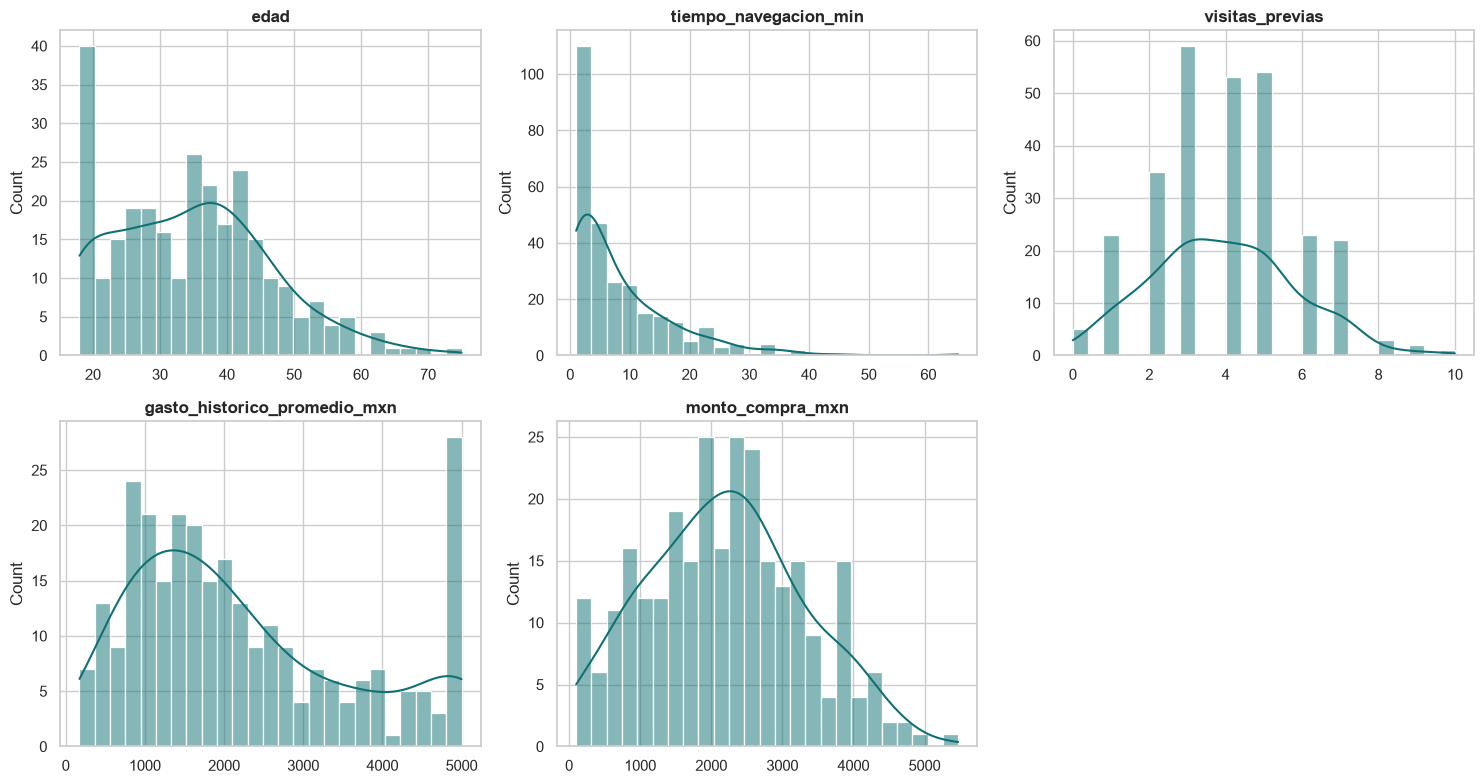

,count,mean,std,min,25%,50%,75%,max
edad,280.0,34.753571,11.786633,18.0,25.0,35.0,42.00,75.0
tiempo_navegacion_min,280.0,8.353571,8.994223,1.0,2.0,5.0,12.00,65.0
visitas_previas,280.0,3.914286,1.856832,0.0,3.0,4.0,5.00,10.0
gasto_historico_promedio_mxn,280.0,2220.721429,1406.547633,174.0,1093.5,1841.0,3099.25,5000.0
monto_compra_mxn,280.0,2195.392857,1109.512872,100.0,1412.0,2199.0,2918.50,5474.0


In [9]:
cont_cols = ["edad", "tiempo_navegacion_min", "visitas_previas",
             "gasto_historico_promedio_mxn", "monto_compra_mxn"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cont_cols):
    sns.histplot(df[col], bins=25, kde=True, color=TEAL, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
axes[-1, -1].axis("off")
plt.tight_layout()
plt.show()

df[cont_cols].describe().T

**Interpretación.** `edad`, `visitas_previas` y `gasto_historico_promedio_mxn` se ven
razonablemente simétricas y bien distribuidas en su rango (aunque `gasto_historico_promedio_mxn`
muestra ese tope en 5,000 mencionado arriba). `tiempo_navegacion_min` está sesgada a la derecha: la
mayoría de las sesiones son cortas, con una cola larga de sesiones más prolongadas. La respuesta,
`monto_compra_mxn`, también está sesgada a la derecha y cubre un rango amplio (\$100 a \$5,474),
sin ningún hueco o agrupamiento evidente, consistente con una mezcla de compras chicas y grandes
entre categorías.

### Variables categóricas

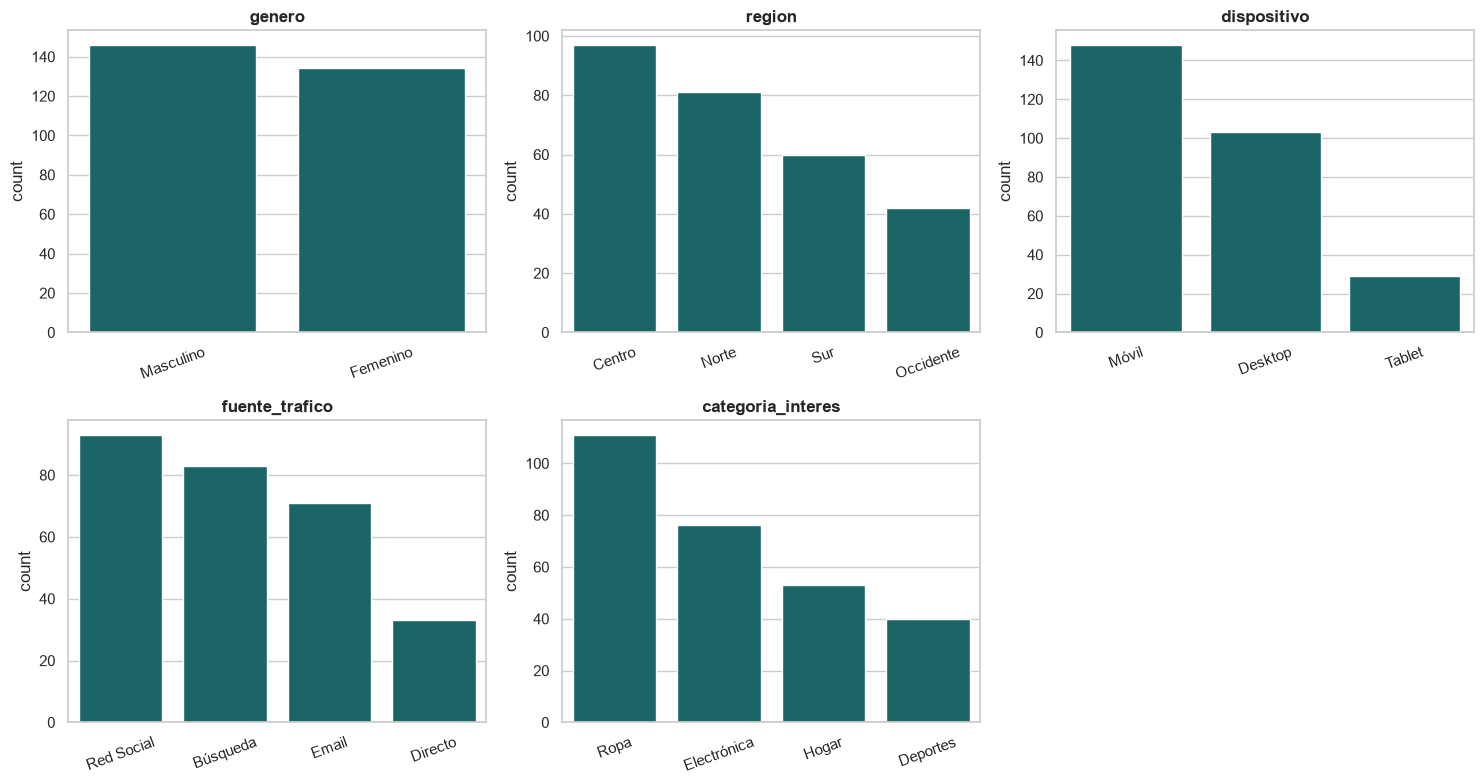

In [10]:
cat_cols = ["genero", "region", "dispositivo", "fuente_trafico", "categoria_interes"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color=TEAL, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
axes[-1, -1].axis("off")
plt.tight_layout()
plt.show()

**Interpretación.** `genero` está casi balanceado (146 Masculino vs. 134 Femenino). Los
otros cuatro factores no están balanceados, pero cada nivel tiene un tamaño de muestra razonable:
`region` va de 42 (Occidente) a 97 (Centro), `dispositivo` está dominado por Móvil (148) con
Tablet como el grupo más chico (29), `fuente_trafico` va de 33 (Directo) a 93 (Red Social), y
`categoria_interes` está dominada por Ropa (111) con Deportes como el más chico (40). Ningún grupo
es tan pequeño como para que su media sea poco confiable, pero el desbalance es algo a tener en
cuenta para el ANOVA más adelante.

### Gasto promedio por categoría (evidencia preliminar)

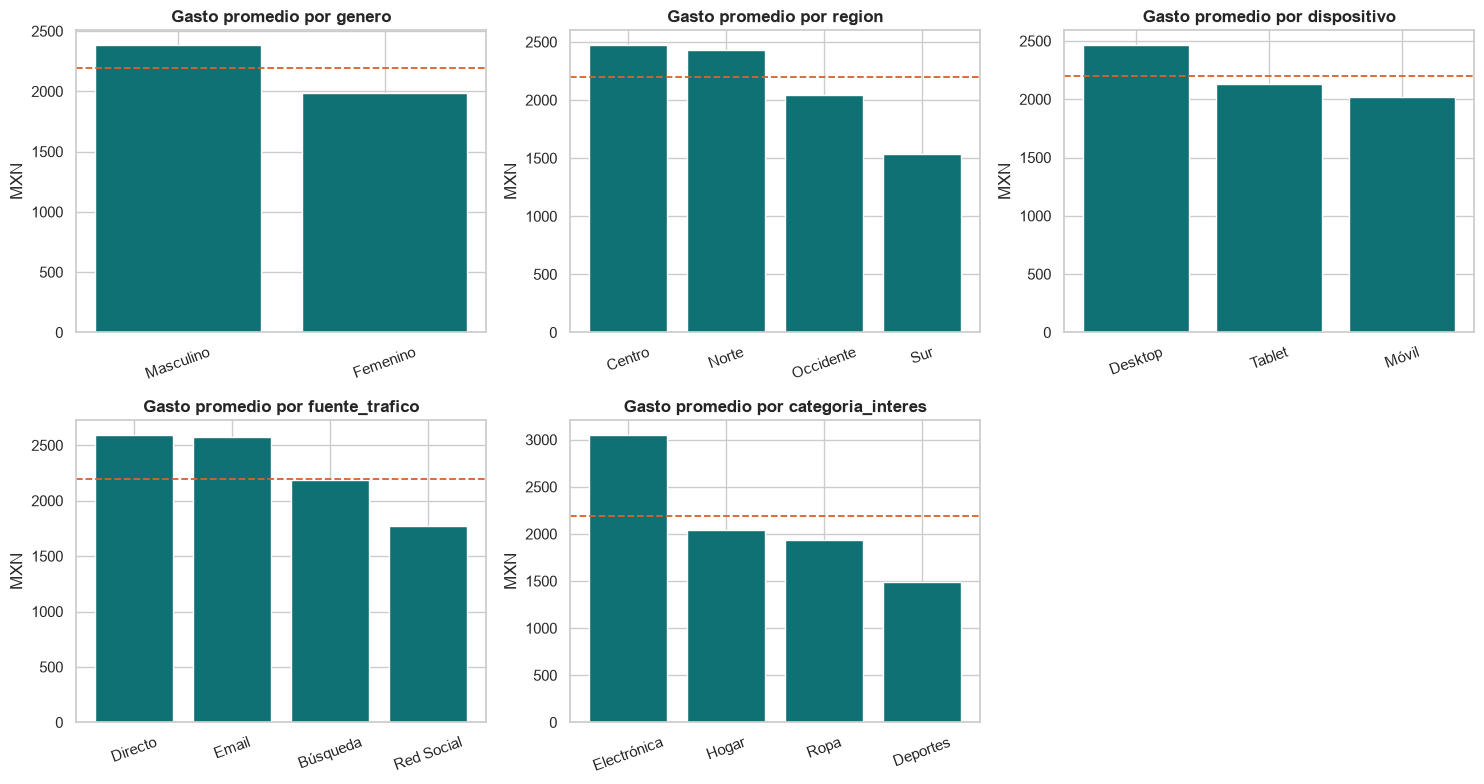

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
overall_mean = df["monto_compra_mxn"].mean()
for ax, col in zip(axes.ravel(), cat_cols):
    means = df.groupby(col)["monto_compra_mxn"].mean().sort_values(ascending=False)
    ax.bar(means.index.astype(str), means.values, color=TEAL)
    ax.axhline(overall_mean, color=CORAL, linestyle="--", linewidth=1.3)
    ax.set_title(f"Gasto promedio por {col}")
    ax.set_ylabel("MXN")
    ax.tick_params(axis="x", rotation=20)
axes[-1, -1].axis("off")
plt.tight_layout()
plt.show()

**Interpretación.** La línea punteada es la media global (~\$2,195 MXN). Estas son
diferencias *crudas*, sin controlar por los demás factores y sin probar todavía si son mayores que
el azar — eso es justamente el trabajo de la regresión y el ANOVA más adelante — pero ya dan una
primera idea de dónde buscar: `categoria_interes` muestra la brecha más grande (Electrónica muy por
arriba, Deportes muy por debajo), seguida de `region` (Sur claramente por debajo) y
`fuente_trafico` (Red Social por debajo del resto). Dentro de cada grupo la desviación estándar
ronda \$900 a \$1,400 MXN, así que hay mucho traslape entre clientes de distintos grupos aunque las
medias difieran.

### Correlación

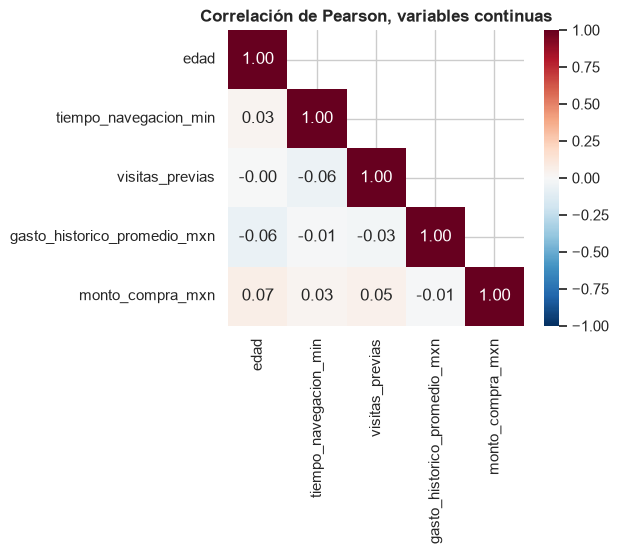

In [12]:
corr = df[cont_cols].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlación de Pearson, variables continuas")
plt.tight_layout()
plt.show()

**Interpretación.** Ninguno de los cuatro predictores continuos se correlaciona de forma
relevante con `monto_compra_mxn` por sí solo (todas las correlaciones están por debajo de 0.07 en
valor absoluto): edad, tiempo de navegación, visitas previas y gasto histórico promedio casi no se
mueven junto con el monto de compra en un sentido lineal simple. Eso no significa que sean
inútiles en una regresión múltiple (una variable puede importar una vez controlando por otras),
pero es una señal temprana de que los factores categóricos como dispositivo, fuente de tráfico o
categoría de producto podrían cargar más peso explicativo que las variables continuas de
comportamiento. Lo confirmamos directamente al ajustar la regresión múltiple abajo. Los
predictores continuos también están débilmente correlacionados entre sí, así que la
multicolinealidad entre ellos no es un problema.

---
# 3. Regresión lineal múltiple

## 3.1 Descripción del problema

**Pregunta de negocio:** ¿qué factores predicen cuánto gasta un cliente, y podemos predecir de
forma confiable el gasto de clientes nuevos?

La regresión lineal múltiple modela `monto_compra_mxn` como una combinación lineal de todas las
demás variables del dataset (edad, tiempo de navegación, visitas previas, gasto histórico, género,
región, dispositivo, fuente de tráfico y categoría de interés). Responde la pregunta de Operaciones
en dos partes:

1. **¿Qué factores importan, y cuánto?** Cada coeficiente estima el cambio en el monto promedio de
   compra (en MXN) asociado a un aumento de una unidad en una variable continua, o a pertenecer a
   una categoría en vez de la categoría de referencia, manteniendo fijas las demás variables.
2. **¿Qué tan bien podemos predecir el gasto de un cliente nuevo?** Ajustamos el modelo en una
   muestra aleatoria del 80% de los clientes (entrenamiento) y evaluamos sus predicciones contra el
   monto de compra del 20% restante (prueba), que el modelo nunca vio al ajustarse. Esto nos dice
   no solo qué tan bien se ajusta a los datos con los que se entrenó, sino qué tan bien generaliza.

Usamos `C()` para que `statsmodels` construya automáticamente las variables dummy de cada
predictor categórico, usando el primer nivel alfabético de cada factor como categoría de
referencia.

In [13]:
train, test = train_test_split(df, test_size=0.2, random_state=42)
print(f"Conjunto de entrenamiento: {train.shape[0]} clientes   Conjunto de prueba: {test.shape[0]} clientes")

formula = (
    "monto_compra_mxn ~ edad + tiempo_navegacion_min + visitas_previas "
    "+ gasto_historico_promedio_mxn + C(genero) + C(region) + C(dispositivo) "
    "+ C(fuente_trafico) + C(categoria_interes)"
)
model = smf.ols(formula, data=train).fit()
print(model.summary())

Conjunto de entrenamiento: 224 clientes   Conjunto de prueba: 56 clientes
                            OLS Regression Results                            
Dep. Variable:       monto_compra_mxn   R-squared:                       0.473
Model:                            OLS   Adj. R-squared:                  0.433
Method:                 Least Squares   F-statistic:                     11.63
Date:                Tue, 22 Sep 2026   Prob (F-statistic):           2.78e-21
Time:                        19:34:49   Log-Likelihood:                -1808.9
No. Observations:                 224   AIC:                             3652.
Df Residuals:                     207   BIC:                             3710.
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------

El resumen del modelo advierte que el **número de condición es grande** (~17,800), lo que
suele indicar multicolinealidad. Lo revisamos formalmente en la sección 3.5, pero se adelanta la
conclusión: **no es multicolinealidad**. El VIF (factor de inflación de varianza) de cada predictor
está por debajo de 2.6 — muy lejos del umbral de preocupación (VIF > 5 o 10). El número de condición
grande viene de la **escala**: `gasto_historico_promedio_mxn` está en miles de pesos mientras que
las variables dummy son 0 o 1. Si se estandarizan las cuatro variables continuas, el número de
condición baja a ~8.9 y el R² no cambia en absoluto. Los coeficientes de la tabla se dejan en
unidades originales de MXN para poder leerlos directamente en pesos.

## 3.2 Prueba F

**H0:** todos los coeficientes son cero (β₁ = β₂ = ... = βₖ = 0). Ninguno de los predictores, en
conjunto, explica variación alguna en `monto_compra_mxn`; el modelo no es mejor que predecir la
media para todos.

**Ha:** al menos un βᵢ ≠ 0. El modelo en su conjunto explica una parte significativa de la
variación en el monto de compra.

In [14]:
f_critico = stats.f.ppf(0.95, model.df_model, model.df_resid)
print(f"Estadístico F:        {model.fvalue:.2f}")
print(f"Grados de libertad:   {int(model.df_model)} (modelo), {int(model.df_resid)} (residual)")
print(f"F crítica (α=0.05):   {f_critico:.3f}")
print(f"Prob (F-statistic):   {model.f_pvalue:.2e}")
print("Decisión:", "rechazar H0" if model.f_pvalue < 0.05 else "no rechazar H0")

Estadístico F:        11.63
Grados de libertad:   16 (modelo), 207 (residual)
F crítica (α=0.05):   1.693
Prob (F-statistic):   2.78e-21
Decisión: rechazar H0


**Interpretación.** F(16, 207) = 11.63, muy por arriba del valor crítico de 1.69 al 5%, con
p = 2.78e-21, muy por debajo de cualquier umbral convencional de 0.05. Rechazamos H0: el modelo en
su conjunto es altamente significativo. El conjunto completo de predictores explica una parte real,
no aleatoria, de la variación en cuánto gasta un cliente. Esto todavía no dice qué predictores
individuales están haciendo el trabajo, solo que el modelo no es inútil en general.

## 3.3 Significancia e interpretación de coeficientes

Para cada coeficiente βᵢ:

**H0:** βᵢ = 0 (la variable, o esa categoría respecto a la categoría de referencia, no tiene efecto
sobre `monto_compra_mxn` una vez que se controla por las demás variables).

**Ha:** βᵢ ≠ 0 (sí tiene efecto).

In [15]:
coef_table = pd.DataFrame({
    "coef": model.params,
    "std_err": model.bse,
    "t": model.tvalues,
    "p_value": model.pvalues,
})
coef_table["significativo (α=0.05)"] = coef_table["p_value"] < 0.05
coef_table.round(4)

,coef,std_err,t,p_value,significativo (α=0.05)
Intercept,1791.9362,310.3754,5.7734,0.0000,True
C(genero)[T.Masculino],331.2225,109.2463,3.0319,0.0027,True
C(region)[T.Norte],-37.2804,137.5131,-0.2711,0.7866,False
C(region)[T.Occidente],-166.5047,177.6510,-0.9373,0.3497,False
C(region)[T.Sur],-792.9769,147.7220,-5.3680,0.0000,True
C(dispositivo)[T.Móvil],-399.4537,121.1479,-3.2972,0.0011,True
C(dispositivo)[T.Tablet],-329.7857,195.7383,-1.6848,0.0935,False
C(fuente_trafico)[T.Directo],-117.1809,192.9922,-0.6072,0.5444,False
C(fuente_trafico)[T.Email],413.3754,148.2363,2.7886,0.0058,True
C(fuente_trafico)[T.Red Social],-498.6845,142.9749,-3.4879,0.0006,True


**Interpretación, solo coeficientes estadísticamente significativos** (categorías de
referencia: `genero`=Femenino, `region`=Centro, `dispositivo`=Desktop, `fuente_trafico`=Búsqueda,
`categoria_interes`=Deportes):

- **Intercepto (\$1,792, p<0.001).** La línea base: una clienta Femenino, región Centro, Desktop,
  llegada por Búsqueda, interesada en Deportes, con edad/navegación/visitas/histórico = 0 (no tiene
  sentido de negocio por sí sola, pero es necesaria para la ecuación).
- **`genero`: Masculino (+\$331, p=0.003).** Manteniendo todo lo demás fijo, los clientes hombres
  gastan en promedio \$331 MXN más por transacción que las clientas mujeres.
- **`region`: Sur (−\$793, p<0.001).** Los clientes del Sur gastan en promedio \$793 MXN menos por
  transacción que clientes idénticos en la región Centro. Norte y Occidente no son
  significativamente distintos de Centro (p=0.787 y p=0.350).
- **`dispositivo`: Móvil (−\$399, p=0.001).** Los clientes que compran desde móvil gastan en
  promedio \$399 MXN menos que clientes idénticos en Desktop. Tablet no es significativamente
  distinto de Desktop (p=0.094, en el límite pero no significativo al 5%).
- **`fuente_trafico`: Email (+\$413, p=0.006).** Los clientes que llegaron por una campaña de
  correo gastan en promedio \$413 MXN más que clientes idénticos llegados por búsqueda.
- **`fuente_trafico`: Red Social (−\$499, p=0.001).** Los clientes que llegaron por redes sociales
  gastan en promedio \$499 MXN menos que clientes idénticos referidos por búsqueda. Directo no es
  significativamente distinto de Búsqueda (p=0.544).
- **`categoria_interes`: Electrónica (+\$1,513, p<0.001), Hogar (+\$545, p=0.007), Ropa (+\$466,
  p=0.008).** Todas las categorías gastan más que la referencia Deportes una vez controlando por
  los demás factores, con Electrónica muy por delante: una compra de electrónica es en promedio
  \$1,513 MXN más alta que una compra idéntica en deportes.

**No estadísticamente significativas:** `edad` (p=0.849), `tiempo_navegacion_min` (p=0.201),
`visitas_previas` (p=0.330), `gasto_historico_promedio_mxn` (p=0.621), `region`: Norte y
Occidente, `dispositivo`: Tablet, `fuente_trafico`: Directo. Ninguna de las cuatro variables
continuas de comportamiento predice el monto de compra una vez que se controla por demografía,
canal y categoría — exactamente el patrón que ya insinuaba el mapa de correlación. El gasto en esta
plataforma está determinado por *quién es el cliente y cómo llegó*, no por cuánto tiempo navegó,
cuántas veces había visitado antes, o cuánto gasta típicamente en promedio.

**Nota sobre `gasto_historico_promedio_mxn`.** Que esta variable no sea significativa es, en
parte, consecuencia del tope en 5,000 detectado en la limpieza: al estar truncada, pierde
variación justo en el extremo alto, donde más ayudaría a distinguir clientes de mayor valor
histórico.

## 3.4 Interpretación de R²

In [16]:
print(f"R-cuadrada:            {model.rsquared:.4f}")
print(f"R-cuadrada ajustada:   {model.rsquared_adj:.4f}")

R-cuadrada:            0.4735
R-cuadrada ajustada:   0.4328


**Interpretación.** R² = 0.473: el modelo explica cerca del 47% de la variación en el monto
de compra entre clientes. R² ajustada = 0.433, cercana a R² a pesar de que el modelo tiene 16
predictores sobre 224 observaciones de entrenamiento, lo que significa que el modelo no está
simplemente sobreajustando con variables que no ayudan; la mayoría de los predictores están
aportando peso real. Poco más de la mitad de la variación en el gasto (el ~53-57% restante) queda
sin explicar por demografía, canal, dispositivo y categoría. Es un ajuste moderado y útil para
negocio, no uno preciso: suficiente para distinguir qué grupos gastan más o menos, no suficiente
para predecir con precisión el gasto de un cliente individual (cuantificamos esa brecha en las
métricas de error más abajo).

## 3.5 Prueba de supuestos

Cuatro supuestos sostienen la validez de las estimaciones de MCO y sus valores p. Se prueban los
cuatro sobre los residuales del conjunto de entrenamiento.

### 3.5.1 Linealidad

**H0:** la relación entre los predictores y `monto_compra_mxn` es lineal (no faltan términos no
lineales).
**Ha:** la relación no es lineal (el modelo está mal especificado).

Usamos la prueba RESET de Ramsey, que agrega potencias de los valores ajustados de vuelta al
modelo y revisa si aportan poder explicativo adicional.

In [17]:
reset_test = linear_reset(model, power=2, use_f=True)
print(reset_test)

<F test: F=0.5956431701457704, p=0.4411296370999954, df_denom=206, df_num=1>


**Interpretación.** F = 0.60, p = 0.441. No rechazamos H0: no hay evidencia de que a la
especificación lineal le falte estructura no lineal importante.

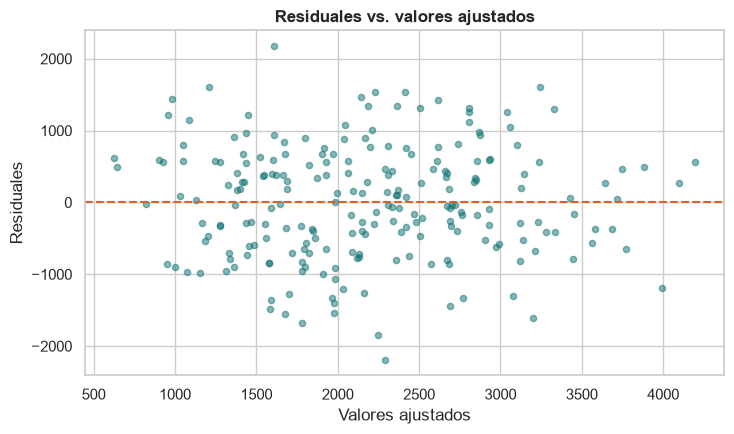

In [18]:
fitted = model.fittedvalues
resid = model.resid

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.scatter(fitted, resid, s=20, alpha=0.5, color=TEAL)
ax.axhline(0, color=CORAL, linestyle="--", linewidth=1.5)
ax.set_xlabel("Valores ajustados")
ax.set_ylabel("Residuales")
ax.set_title("Residuales vs. valores ajustados")
plt.tight_layout()
plt.show()

La gráfica de residuales contra valores ajustados lo confirma visualmente: los puntos se
dispersan en una banda alrededor de cero sin forma de curva o de embudo conforme aumentan los
valores ajustados.

### 3.5.2 Independencia de los errores

**H0:** los residuales no están autocorrelacionados (cada error es independiente de los demás).
**Ha:** los residuales están autocorrelacionados.

Usamos la prueba de Breusch-Godfrey (formal, con valor p), junto con el estadístico
Durbin-Watson como referencia complementaria.

In [19]:
dw = durbin_watson(resid)
print(f"Estadístico Durbin-Watson: {dw:.3f}  (cercano a 2.0 = sin autocorrelación)")

bg_lm, bg_p, bg_f, bg_fp = acorr_breusch_godfrey(model, nlags=1)
print(f"\nBreusch-Godfrey LM: {bg_lm:.3f}, valor p: {bg_p:.3f}")

Estadístico Durbin-Watson: 1.965  (cercano a 2.0 = sin autocorrelación)

Breusch-Godfrey LM: 0.067, valor p: 0.796


C:\Users\hecto\AppData\Local\Temp\ipykernel_25268\2908917189.py:4: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg_lm, bg_p, bg_f, bg_fp = acorr_breusch_godfrey(model, nlags=1)


**Interpretación.** Durbin-Watson = 1.965, esencialmente el 2.0 que indica ausencia de
autocorrelación, y la prueba de Breusch-Godfrey coincide (p = 0.796). No rechazamos H0: no hay
evidencia de errores autocorrelacionados. Esto es lo esperado aquí, ya que las filas son clientes
independientes sin un orden temporal o secuencial natural.

### 3.5.3 Homoscedasticidad

**H0:** la varianza de los residuales es constante en todos los niveles de los predictores
(homoscedasticidad).
**Ha:** la varianza de los residuales cambia con los predictores (heteroscedasticidad).

Usamos la prueba de Breusch-Pagan.

In [20]:
bp_lm, bp_p, bp_f, bp_fp = het_breuschpagan(resid, model.model.exog)
print(f"Breusch-Pagan LM: {bp_lm:.3f}, valor p: {bp_p:.3f}")

Breusch-Pagan LM: 12.464, valor p: 0.712


**Interpretación.** p = 0.727. No rechazamos H0: no hay evidencia de que la varianza de los
residuales cambie con los valores de los predictores. Los errores estándar de los coeficientes de
arriba, y por lo tanto la prueba F y las pruebas t, son confiables sin necesitar una corrección
robusta a heteroscedasticidad.

### 3.5.4 Normalidad de los residuales

**H0:** los residuales se distribuyen normalmente.
**Ha:** los residuales no se distribuyen normalmente.

Usamos Shapiro-Wilk y Jarque-Bera como dos pruebas independientes, junto con un gráfico Q-Q.

Shapiro-Wilk:  W = 0.9956, valor p = 0.766
Jarque-Bera:   JB = 1.071, valor p = 0.585
Sesgo (skewness): -0.038   Curtosis: 2.670


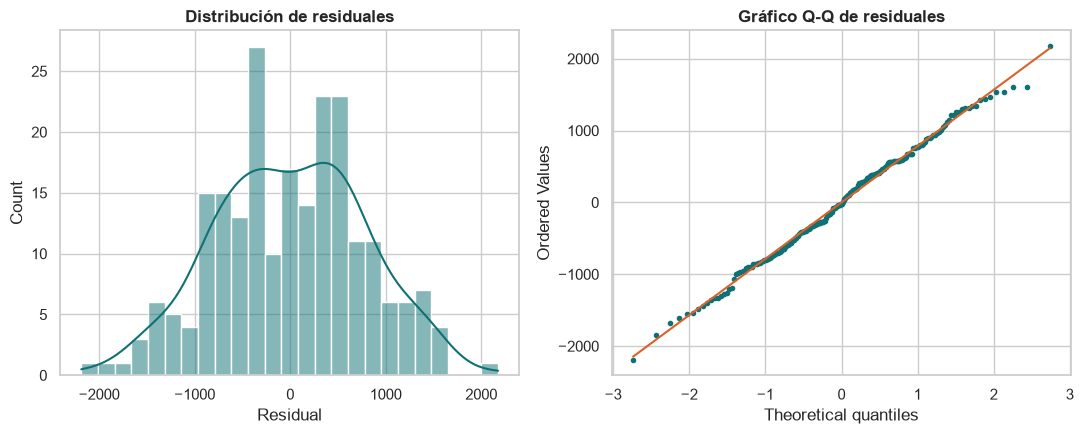

In [21]:
shapiro_stat, shapiro_p = stats.shapiro(resid)
jb_stat, jb_p, jb_skew, jb_kurt = jarque_bera(resid)
print(f"Shapiro-Wilk:  W = {shapiro_stat:.4f}, valor p = {shapiro_p:.3f}")
print(f"Jarque-Bera:   JB = {jb_stat:.3f}, valor p = {jb_p:.3f}")
print(f"Sesgo (skewness): {jb_skew:.3f}   Curtosis: {jb_kurt:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.histplot(resid, bins=25, kde=True, color=TEAL, ax=axes[0])
axes[0].set_title("Distribución de residuales")
axes[0].set_xlabel("Residual")

stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q de residuales")
axes[1].get_lines()[0].set_color(TEAL)
axes[1].get_lines()[0].set_markersize(3)
axes[1].get_lines()[1].set_color(CORAL)

plt.tight_layout()
plt.show()

**Interpretación.** Shapiro-Wilk: p = 0.766. Jarque-Bera: p = 0.585, con sesgo de −0.04 y
curtosis de 2.67, ambos cercanos a los valores normales de 0 y 3. Las dos pruebas coinciden: no
rechazamos H0. Los residuales son consistentes con una distribución normal, confirmado visualmente
por el histograma con forma aproximadamente de campana y los puntos del gráfico Q-Q pegados a la
línea de referencia en casi todo el rango.

**Los cuatro supuestos se cumplen.** Linealidad, independencia, homoscedasticidad y normalidad se
satisfacen en los datos de entrenamiento, lo que significa que las estimaciones de coeficientes,
errores estándar y valores p reportados arriba se pueden interpretar tal cual.

## 3.6 Predicción del monto de compra

Usamos ahora el modelo ajustado en el conjunto de entrenamiento para predecir `monto_compra_mxn`
de los 56 clientes del conjunto de prueba, que no participó en el ajuste del modelo.

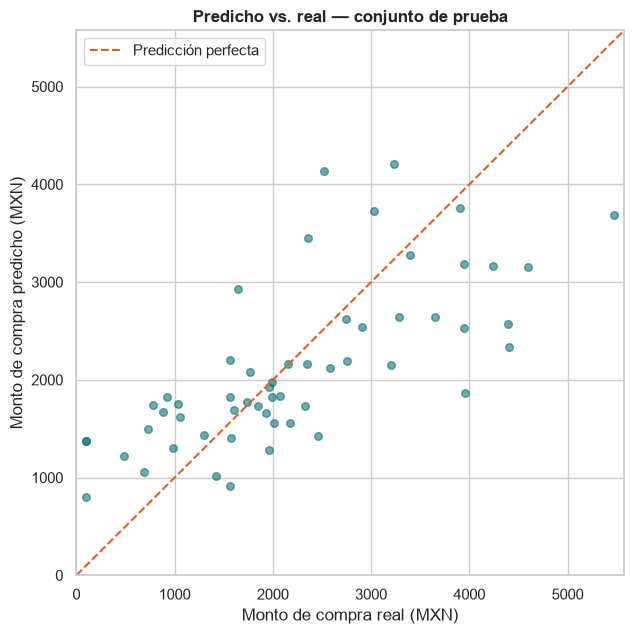

Correlación predicho-real: 0.710   (R² efectiva en prueba: 0.505)
% de predicciones a menos de $500 MXN del valor real:  41.1%
% de predicciones a menos de $1,000 MXN del valor real: 73.2%


In [22]:
test_pred = model.predict(test)
test_actual = test["monto_compra_mxn"]

fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(test_actual, test_pred, s=30, alpha=0.6, color=TEAL)
lims = [min(test_actual.min(), test_pred.min()) - 100, max(test_actual.max(), test_pred.max()) + 100]
ax.plot(lims, lims, color=CORAL, linestyle="--", linewidth=1.5, label="Predicción perfecta")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Monto de compra real (MXN)")
ax.set_ylabel("Monto de compra predicho (MXN)")
ax.set_title("Predicho vs. real — conjunto de prueba")
ax.legend()
plt.tight_layout()
plt.show()

corr_pred = np.corrcoef(test_actual, test_pred)[0, 1]
within_500 = ((test_actual - test_pred).abs() <= 500).mean()
within_1000 = ((test_actual - test_pred).abs() <= 1000).mean()
print(f"Correlación predicho-real: {corr_pred:.3f}   (R² efectiva en prueba: {corr_pred**2:.3f})")
print(f"% de predicciones a menos de $500 MXN del valor real:  {within_500:.1%}")
print(f"% de predicciones a menos de $1,000 MXN del valor real: {within_1000:.1%}")

**Interpretación.** Los puntos se agrupan de forma dispersa alrededor de la línea diagonal
de 45° (predicción perfecta), sin un sesgo direccional claro, consistente con una R² efectiva en
prueba de 0.50 (correlación predicho-real de 0.71), muy parecida a la R² de entrenamiento (0.47) —
el modelo no se desmorona con clientes nuevos. En términos prácticos: 41% de las predicciones caen
a menos de \$500 MXN del valor real, y 73% a menos de \$1,000 MXN.

El modelo falla más con clientes cuyo comportamiento no coincide con el de su segmento. Los errores
más grandes son compras altas **subestimadas** (por ejemplo, un cliente del Sur que gastó \$3,954
MXN cuando el modelo esperaba ~\$1,860, o el máximo de la muestra, \$5,474 MXN, predicho en solo
~\$3,683) y, en menor medida, algunas compras **sobrestimadas** en perfiles que el modelo espera
altos por categoría/canal/dispositivo pero que en realidad gastaron poco. En general: el modelo es
más útil para ordenar segmentos (qué grupo tiende a gastar más) que para fijar el gasto exacto de
un cliente en particular, y es menos confiable justo en los extremos de la distribución.

## 3.7 Cálculo de errores

In [23]:
mae = mean_absolute_error(test_actual, test_pred)
mape = mean_absolute_percentage_error(test_actual, test_pred)
rmse = mean_squared_error(test_actual, test_pred) ** 0.5

print(f"MAE:  $ {mae:,.0f}")
print(f"MAPE: {mape:.1%}")
print(f"RMSE: $ {rmse:,.0f}")
print(f"\nDe referencia, gasto real promedio en el conjunto de prueba: $ {test_actual.mean():,.0f}")

MAE:  $ 699
MAPE: 90.8%
RMSE: $ 881

De referencia, gasto real promedio en el conjunto de prueba: $ 2,238


In [24]:
# El MAPE es sensible a denominadores chicos. Lo diagnosticamos directamente.
ape = (test_actual - test_pred).abs() / test_actual
peor = pd.DataFrame({"real": test_actual, "predicho": test_pred.round(0), "APE": ape}) \
    .sort_values("APE", ascending=False).head(5)
print(peor)
print(f"\nAPE mediana: {ape.median():.1%}")
print(f"MAPE excluyendo compras menores a $500: {mean_absolute_percentage_error(test_actual[test_actual>=500], test_pred[test_actual>=500]):.1%}")

     real  predicho        APE
60    100    1379.0  12.785174
46    100    1375.0  12.745313
30    100     802.0   7.020902
24    482    1218.0   1.527127
262   780    1744.0   1.235873

APE mediana: 28.4%
MAPE excluyendo compras menores a $500: 32.2%


**Interpretación.**

- **MAE ≈ \$699.** En promedio, una predicción se equivoca en unos \$699 MXN respecto al monto
  real, en cualquier dirección. Contra un gasto promedio de \$2,238 en el conjunto de prueba, eso
  es un error típico de alrededor del 31% en términos absolutos.
- **RMSE ≈ \$881.** Mayor que el MAE, como se espera, ya que RMSE penaliza más los errores grandes;
  la diferencia entre ambos confirma que algunas predicciones están considerablemente más
  desviadas que el caso típico (visible en el extremo inferior izquierdo de la gráfica de
  predicción de arriba).
- **MAPE ≈ 91%**, pero esta cifra es engañosa por sí sola y no debe citarse aislada. Está inflada
  por tres clientes de prueba cuya compra real fue exactamente \$100 (el piso práctico del
  dataset, ya identificado en la limpieza): un error de \$700–\$1,300 sobre una compra de \$100
  produce un APE de 700%–1,280%, y esas tres filas por sí solas jalan el promedio muy por arriba de
  lo que se ve en un caso típico. La **mediana** del APE es 28%, y el MAPE calculado solo sobre
  compras de \$500 o más (52 de las 56 filas de prueba) baja a 32%, ambos mucho más representativos
  del desempeño típico del modelo. Esta es una debilidad conocida del MAPE cuando la respuesta
  puede acercarse a cero, y vale la pena señalarla directamente a Operaciones: reportar MAE y RMSE
  como las métricas de error principales para este modelo, y tratar el MAPE general con
  precaución.

## 3.8 Perfil de cliente ilustrativo

Para hacer tangible la ecuación, la aplicamos a dos perfiles hipotéticos que comparten el mismo
valor promedio de edad, tiempo de navegación, visitas previas e historial de gasto, y solo cambian
en género, canal y categoría de interés.

In [25]:
perfil_promedio = train[["edad", "tiempo_navegacion_min", "visitas_previas", "gasto_historico_promedio_mxn"]].mean()

referencia = {
    "edad": perfil_promedio["edad"],
    "tiempo_navegacion_min": perfil_promedio["tiempo_navegacion_min"],
    "visitas_previas": perfil_promedio["visitas_previas"],
    "gasto_historico_promedio_mxn": perfil_promedio["gasto_historico_promedio_mxn"],
    "genero": "Femenino", "region": "Centro", "dispositivo": "Desktop",
    "fuente_trafico": "Búsqueda", "categoria_interes": "Deportes",
}
alto_valor = {**referencia, "genero": "Masculino", "fuente_trafico": "Email", "categoria_interes": "Electrónica"}

perfiles = pd.DataFrame([referencia, alto_valor], index=["Perfil de referencia", "Perfil de alto ticket"])
perfiles["monto_predicho_mxn"] = model.predict(perfiles).round(0)
perfiles[["genero", "region", "dispositivo", "fuente_trafico", "categoria_interes", "monto_predicho_mxn"]]

,genero,region,dispositivo,fuente_trafico,categoria_interes,monto_predicho_mxn
Perfil de referencia,Femenino,Centro,Desktop,Búsqueda,Deportes,1826.0
Perfil de alto ticket,Masculino,Centro,Desktop,Email,Electrónica,4084.0


**Interpretación.** Con el resto del perfil idéntico (edad, navegación, visitas e historial
en su promedio), cambiar de una clienta Femenino/Búsqueda/Deportes a un cliente
Masculino/Email/Electrónica eleva la predicción de ~\$1,826 a ~\$4,084 MXN, una diferencia de
~\$2,258 MXN que viene casi toda de la categoría de interés y del canal, con una contribución menor
del género. Esto ilustra en pesos concretos lo que dicen los coeficientes: la categoría de producto
es, por mucho, la palanca más grande que el modelo identifica.

## 3.9 Conclusión

**¿Qué factores importan más?** El monto de compra está determinado casi por completo por *quién
es el cliente y cómo llegó*, no por su comportamiento de navegación. `categoria_interes` tiene por
mucho los efectos más grandes (los clientes interesados en Electrónica gastan ~\$1,513 MXN más que
los de Deportes, todo lo demás igual), seguida de `region` (los clientes del Sur gastan ~\$793 MXN
menos que los de Centro), el dispositivo (Móvil gasta ~\$399 MXN menos que Desktop), la fuente de
tráfico (Email es el mejor canal con +\$413 vs. Búsqueda, Red Social el peor con −\$499), y el
género (los hombres gastan ~\$331 MXN más). Edad, tiempo de navegación, número de visitas previas y
gasto histórico promedio no muestran relación estadísticamente significativa con el monto de
compra una vez controlando por esos otros factores.

**¿Qué tan bueno es el modelo?** Explica cerca del 47% de la variación en el gasto (R²=0.473, R²
ajustada=0.433) y pasa limpiamente las cuatro pruebas de supuestos, así que los coeficientes de
arriba son confiables. En clientes nuevos predice dentro de ~\$699 MXN en promedio (MAE), útil para
comparar segmentos pero no lo bastante preciso para cotizar una transacción individual con
confianza — la gráfica de predicción muestra dispersión real alrededor de la línea ideal, sobre
todo en los extremos de la distribución.

**¿Qué debería hacer Operaciones con esto?** Usar el modelo para priorizar *segmentos*, no
clientes individuales: impulsar la categoría Electrónica y el canal Email, investigar por qué el
Sur y Móvil rinden varios cientos de pesos menos por transacción que Centro y Desktop
(¿experiencia del sitio? ¿percepción de precio local? ¿fricción en el checkout móvil?), y dejar de
intentar predecir el gasto a partir del tiempo de navegación o el historial de visitas, ya que
ninguno de los dos aporta señal aquí. Como todavía queda variación importante sin explicar, tratar
la salida del modelo como un insumo de planeación direccional (mezcla de ingresos por segmento,
personal por canal) y no como un pronóstico a nivel de transacción individual.

---
# 4. ANOVA

## 4.1 Descripción del problema

**Pregunta de negocio:** ¿realmente los grupos de clientes (región, género, dispositivo o fuente
de tráfico) gastan montos distintos, o la diferencia es solo variación aleatoria?

El ANOVA (Análisis de Varianza) prueba si la media de `monto_compra_mxn` difiere entre los niveles
de uno o más factores categóricos, comparando la varianza *entre* medias de grupo contra la
varianza *dentro* de los grupos. Si la varianza entre grupos es grande respecto a la varianza
dentro de los grupos, es poco probable que las diferencias se deban solo al azar. A diferencia de
la regresión de arriba (que controla todas las variables a la vez y estima un efecto en pesos), el
ANOVA aquí está construido específicamente para responder la pregunta de Marketing en sus propios
términos: ¿es real, estadísticamente, la brecha entre la región Sur y la región Centro?, y si el
efecto de un factor depende de otro (una interacción), la estrategia regional y la estrategia de
canal no se pueden planear de forma independiente.

## 4.2 Diagramas de caja

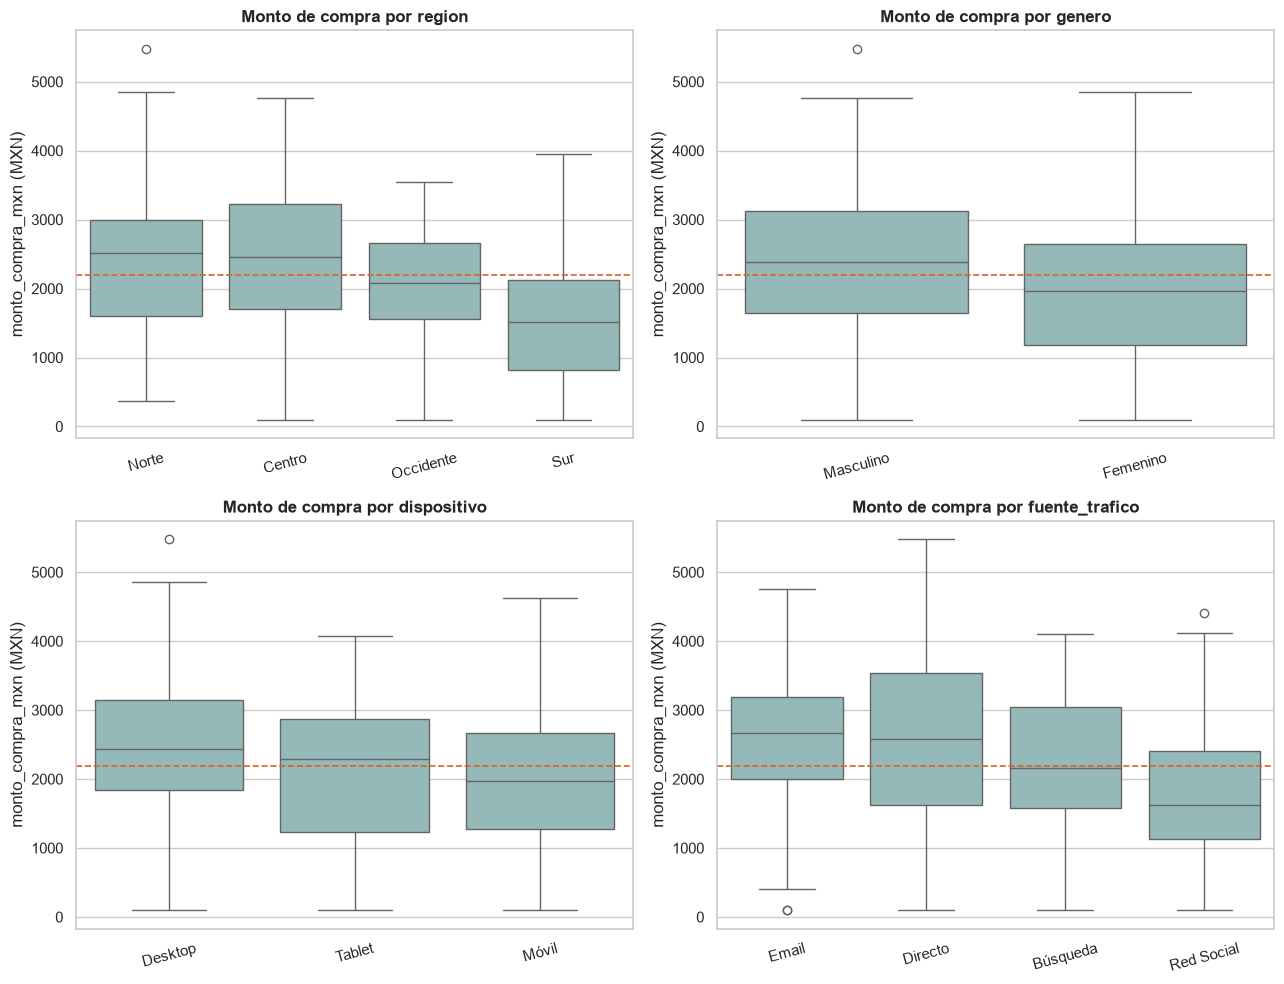

ANOVA de una vía por factor (evidencia de apoyo a los diagramas de caja)


,factor,niveles,F,p_value,decisión
0,region,4,11.7105,0.0000,Rechazar H0
1,genero,2,9.2568,0.0026,Rechazar H0
2,dispositivo,3,5.1211,0.0065,Rechazar H0
3,fuente_trafico,4,9.5366,0.0000,Rechazar H0
4,categoria_interes,4,29.8846,0.0000,Rechazar H0


In [26]:
factores = ["region", "genero", "dispositivo", "fuente_trafico"]

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, factor in zip(axes.ravel(), factores):
    order = df.groupby(factor)["monto_compra_mxn"].median().sort_values(ascending=False).index
    sns.boxplot(data=df, x=factor, y="monto_compra_mxn", order=order, color="#8FBFBF", ax=ax)
    ax.axhline(df["monto_compra_mxn"].mean(), color=CORAL, linestyle="--", linewidth=1.2)
    ax.set_title(f"Monto de compra por {factor}")
    ax.set_xlabel("")
    ax.set_ylabel("monto_compra_mxn (MXN)")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

print("ANOVA de una vía por factor (evidencia de apoyo a los diagramas de caja)")
filas_1via = []
for factor in ["region", "genero", "dispositivo", "fuente_trafico", "categoria_interes"]:
    grupos = [g["monto_compra_mxn"].to_numpy() for _, g in df.groupby(factor)]
    f_stat, p_val = stats.f_oneway(*grupos)
    filas_1via.append({"factor": factor, "niveles": df[factor].nunique(), "F": f_stat, "p_value": p_val,
                        "decisión": "Rechazar H0" if p_val < 0.05 else "No rechazar H0"})
pd.DataFrame(filas_1via).round(4)

**Interpretación.** Las cajas se traslapan de forma considerable en todos los paneles — la
pertenencia a un grupo no determina el ticket de un cliente en particular, pero sí desplaza el
centro de la caja. Eso es consistente con la regresión: los segmentos difieren en promedio, pero
un cliente dentro de un segmento todavía puede variar por ~\$1,000 MXN respecto a otro del mismo
segmento.

- **Región:** la caja de Sur está claramente más abajo que las demás; su mediana (~\$1,539 MXN)
  contrasta con ~\$2,475 en Centro y ~\$2,427 en Norte, con Occidente en medio (~\$2,042).
- **Género:** la caja de Masculino está un poco arriba de Femenino, con traslape considerable.
- **Dispositivo:** Desktop está arriba de Móvil y Tablet, que están más cerca entre sí.
- **Fuente de tráfico:** Red Social está claramente abajo de las otras tres, que se traslapan
  bastante entre sí.

El ANOVA de una vía (tabla de arriba) rechaza H0 para los **cinco** factores al 5%, incluyendo
`categoria_interes`, que tiene el F más grande de todos (29.9) — más que `region` o
`fuente_trafico`. Aun así, elegimos `region` y `fuente_trafico` para el modelo factorial de la
siguiente sección porque son las dos palancas que Marketing puede accionar directamente (a qué
región priorizar, qué canal de adquisición financiar), mientras que la categoría de interés es más
un atributo del cliente que una decisión de canal. Estas pruebas de una vía no controlan por el
otro factor ni prueban interacción — eso es justamente lo que hace el modelo de la sección
siguiente.

## 4.3 Entrenamiento del modelo

**Factores elegidos:** `region` (4 niveles: Centro, Norte, Occidente, Sur) y `fuente_trafico` (4
niveles: Búsqueda, Directo, Email, Red Social), ajustados como un **diseño factorial 4×4 (16
celdas)** con su término de interacción.

$$\text{monto\_compra\_mxn} = \mu + \alpha_i(\text{region}) + \beta_j(\text{fuente\_trafico}) + (\alpha\beta)_{ij} + \varepsilon$$

donde $(\alpha\beta)_{ij}$ es el término de interacción: prueba si el efecto de la fuente de
tráfico sobre el gasto es el *mismo* en cada región, o si depende de en qué región está el
cliente.

**Sobre el tipo de suma de cuadrados.** Como el diseño está desbalanceado (las celdas
región×fuente_trafico van de 5 a 32 clientes) y el modelo incluye la interacción, usamos suma de
cuadrados **Tipo III con codificación de suma (deviation coding)** — `C(factor, Sum)` — en vez del
Tipo II. El Tipo II prueba cada efecto principal asumiendo que la interacción es cero, lo cual deja
de ser el supuesto correcto en cuanto la interacción resulta significativa (como ocurre aquí). El
Tipo III con codificación de suma prueba cada efecto principal controlando por todo lo demás,
incluida la interacción, que es la comparación correcta una vez que la interacción está en el
modelo.

In [27]:
print("Clientes por celda (región x fuente_trafico):")
print(pd.crosstab(df["region"], df["fuente_trafico"]))

anova_model = smf.ols("monto_compra_mxn ~ C(region, Sum) * C(fuente_trafico, Sum)", data=df).fit()
aov_table = anova_lm(anova_model, typ=3)
print(f"\nR² del modelo ANOVA: {anova_model.rsquared:.3f}")
aov_table.round(4)

Clientes por celda (región x fuente_trafico):
fuente_trafico  Búsqueda  Directo  Email  Red Social
region                                              
Centro                32       10     23          32
Norte                 21       12     25          23
Occidente              9        5      8          20
Sur                   21        6     15          18

R² del modelo ANOVA: 0.253


,sum_sq,df,F,PR(>F)
Intercept,1.008008e+09,1.0,1036.5579,0.0000
"C(region, Sum)",4.119707e+07,3.0,14.1213,0.0000
"C(fuente_trafico, Sum)",2.499609e+07,3.0,8.5680,0.0000
"C(region, Sum):C(fuente_trafico, Sum)",1.719104e+07,9.0,1.9642,0.0437
Residual,2.567287e+08,264.0,NaN,NaN


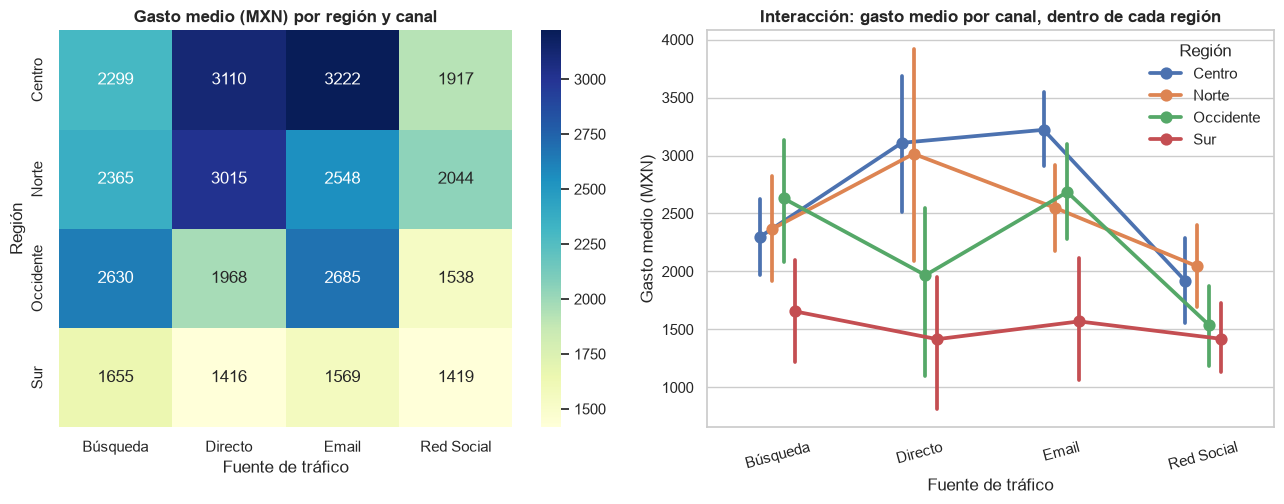

In [28]:
medias_celda = df.pivot_table(index="region", columns="fuente_trafico",
                               values="monto_compra_mxn", aggfunc="mean")
orden_region = ["Centro", "Norte", "Occidente", "Sur"]
orden_fuente = ["Búsqueda", "Directo", "Email", "Red Social"]
medias_celda = medias_celda.reindex(index=orden_region, columns=orden_fuente)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
sns.heatmap(medias_celda, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Gasto medio (MXN) por región y canal")
axes[0].set_xlabel("Fuente de tráfico")
axes[0].set_ylabel("Región")

sns.pointplot(data=df, x="fuente_trafico", y="monto_compra_mxn", hue="region",
              order=orden_fuente, hue_order=orden_region, errorbar=("ci", 95),
              dodge=0.25, ax=axes[1])
axes[1].set_title("Interacción: gasto medio por canal, dentro de cada región")
axes[1].set_xlabel("Fuente de tráfico")
axes[1].set_ylabel("Gasto medio (MXN)")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Región", frameon=False)
plt.tight_layout()
plt.show()

## 4.4 Interpretación de resultados

**Efecto principal de `region`**
**H0:** la media de gasto es igual en las cuatro regiones, una vez controlando por fuente de
tráfico y la interacción.
**Ha:** al menos una región tiene una media de gasto distinta.

**Efecto principal de `fuente_trafico`**
**H0:** la media de gasto es igual en las cuatro fuentes de tráfico, una vez controlando por región
y la interacción.
**Ha:** al menos una fuente de tráfico tiene una media de gasto distinta.

**Interacción `region` × `fuente_trafico`**
**H0:** no hay interacción; la diferencia entre fuentes de tráfico es la misma en cada región.
**Ha:** sí hay interacción; la diferencia entre fuentes de tráfico depende de la región.

**Interpretación.**

| Efecto | F | valor p | Decisión |
|---|---:|---:|---|
| Región | 14.12 | < 0.001 | Rechazar H0 |
| Fuente de tráfico | 8.57 | < 0.001 | Rechazar H0 |
| Región × fuente de tráfico | 1.96 | 0.044 | Rechazar H0 |

Los tres efectos son significativos. Región y fuente de tráfico desplazan el gasto por sí solos, y
la interacción también es significativa, aunque es la más débil de las tres (p=0.044, justo por
debajo de 5%). El ranking de canales no es perfectamente constante entre regiones, pero tampoco es
un negocio completamente distinto en cada una.

El mapa de calor y la gráfica de interacción lo hacen concreto:

- **Centro + Email** (~\$3,222 MXN) y **Centro + Directo** (~\$3,110 MXN) son las celdas más
  altas. **Norte + Directo** también es alto (~\$3,015 MXN), pero Norte + Email es más bajo que
  Centro + Email (~\$2,548 MXN) — la ventaja de Email es más clara específicamente en Centro. Esa
  es la interacción.
- **Red Social es bajo en todas las regiones**, y el más bajo en Occidente (~\$1,538 MXN) y Sur
  (~\$1,419 MXN).
- **El Sur es bajo en todos los canales** (~\$1,416 a \$1,655 MXN). En el Sur, ni Email ni Directo
  reproducen la prima que tienen en Centro — en la gráfica de interacción, las líneas del Sur se
  quedan planas y por debajo de las demás regiones.

La R² del modelo ANOVA es de apenas ~0.25: región y canal, aún con su interacción, explican menos
del ticket que la regresión completa, porque esta última también incluye categoría, dispositivo y
género. Es lo esperado — este modelo responde una pregunta más acotada. Las pruebas de efecto
principal dicen que los grupos difieren, pero no dicen *cuál par* difiere — eso es el test de
Tukey a continuación.

## 4.5 Prueba de supuestos

Dos supuestos sostienen las pruebas F del ANOVA de arriba.

### 4.5.1 Normalidad de los residuales

**H0:** los residuales del ANOVA se distribuyen normalmente.
**Ha:** los residuales del ANOVA no se distribuyen normalmente.

Shapiro-Wilk: W = 0.9929, valor p = 0.207


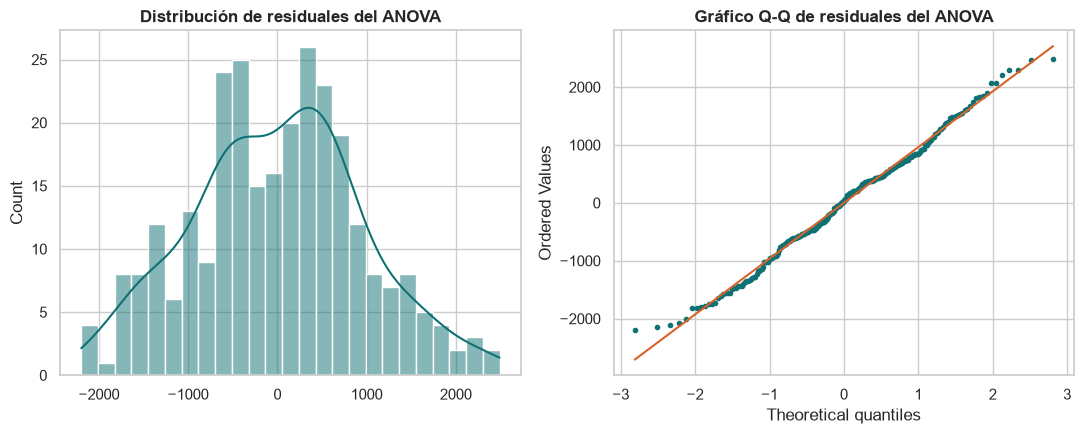

In [29]:
aov_resid = anova_model.resid

shapiro_stat2, shapiro_p2 = stats.shapiro(aov_resid)
print(f"Shapiro-Wilk: W = {shapiro_stat2:.4f}, valor p = {shapiro_p2:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.histplot(aov_resid, bins=25, kde=True, color=TEAL, ax=axes[0])
axes[0].set_title("Distribución de residuales del ANOVA")

stats.probplot(aov_resid, dist="norm", plot=axes[1])
axes[1].set_title("Gráfico Q-Q de residuales del ANOVA")
axes[1].get_lines()[0].set_color(TEAL)
axes[1].get_lines()[0].set_markersize(3)
axes[1].get_lines()[1].set_color(CORAL)

plt.tight_layout()
plt.show()

**Interpretación.** p = 0.207. No rechazamos H0: los residuales son consistentes con
normalidad, respaldado por el histograma con forma de campana y los puntos del Q-Q pegados a la
línea de referencia. No se prueba normalidad celda por celda: varias celdas tienen solo 5 o 6
clientes (Occidente×Directo tiene 5, Sur×Directo tiene 6), y una prueba de Shapiro sobre 5 puntos
tiene muy poco poder estadístico. La prueba sobre los 280 residuales del modelo ajustado es la
verificación relevante para el estadístico F.

### 4.5.2 Homogeneidad de varianzas

**H0:** la varianza de `monto_compra_mxn` es igual en las 16 celdas región × fuente de tráfico
(homoscedasticidad).
**Ha:** la varianza difiere entre celdas.

Usamos la prueba de Levene, calculada sobre las 16 celdas región×fuente_trafico para coincidir con
el modelo factorial de arriba.

In [30]:
df["_celda"] = df["region"].astype(str) + " / " + df["fuente_trafico"].astype(str)
grupos_celda = [g["monto_compra_mxn"].values for _, g in df.groupby("_celda")]
levene_stat, levene_p = stats.levene(*grupos_celda)
print(f"Estadístico de Levene: {levene_stat:.3f}, valor p: {levene_p:.3f}")

Estadístico de Levene: 1.644, valor p: 0.063


**Interpretación.** p = 0.063. No rechazamos H0 al 5%: no hay evidencia estadísticamente
significativa de que las varianzas difieran entre celdas, aunque el valor p está lo bastante cerca
de 0.05 como para señalarlo como una advertencia leve en vez de un resultado cómodo — algunas
celdas con muy pocos clientes probablemente agregan ruido a esta prueba. Junto con el resultado de
normalidad, los supuestos del ANOVA se cumplen razonablemente y las pruebas F de arriba son
confiables, con esa salvedad en mente.

## 4.6 Prueba de Tukey

Las pruebas F globales dicen *que* región y fuente de tráfico importan; la prueba HSD de Tukey dice
*qué pares específicos* de grupos difieren, controlando la tasa de error familiar (FWER) a través de
todas las comparaciones.

In [31]:
print("Tukey HSD — región")
tukey_region = pairwise_tukeyhsd(df["monto_compra_mxn"], df["region"], alpha=0.05)
print(tukey_region)

print("\nTukey HSD — fuente_trafico")
tukey_fuente = pairwise_tukeyhsd(df["monto_compra_mxn"], df["fuente_trafico"], alpha=0.05)
print(tukey_fuente)

Tukey HSD — región


      Multiple Comparison of Means - Tukey HSD, FWER=0.05       
  group1    group2   meandiff p-adj    lower      upper   reject
----------------------------------------------------------------
   Centro     Norte  -48.6711 0.9899  -457.4257  360.0835  False
   Centro Occidente -433.5697 0.1167  -935.1933   68.0539  False
   Centro       Sur -936.3983    0.0 -1382.4337 -490.3628   True
    Norte Occidente -384.8986 0.2193  -901.2751  131.4779  False
    Norte       Sur -887.7272    0.0 -1350.2918 -425.1625   True
Occidente       Sur -502.8286 0.0836  -1049.191   43.5339  False
----------------------------------------------------------------

Tukey HSD — fuente_trafico


      Multiple Comparison of Means - Tukey HSD, FWER=0.05       
 group1    group2    meandiff p-adj    lower      upper   reject
----------------------------------------------------------------
Búsqueda    Directo  405.5425 0.2497  -159.2828  970.3678  False
Búsqueda      Email  386.2143 0.1126   -57.4692  829.8979  False
Búsqueda Red Social -418.0557 0.0471  -832.4912   -3.6202   True
 Directo      Email  -19.3282 0.9998   -597.573  558.9165  False
 Directo Red Social -823.5982 0.0009 -1379.7176 -267.4789   True
   Email Red Social   -804.27    0.0 -1236.8162 -371.7239   True
----------------------------------------------------------------


**Interpretación de los efectos principales.**

- **Región:** solo dos pares son significativamente distintos: **Sur gasta significativamente
  menos que Centro** (−\$936, p<0.001) **y que Norte** (−\$888, p<0.001). Centro vs. Norte, Centro
  vs. Occidente, Norte vs. Occidente, y Occidente vs. Sur son todos estadísticamente indistinguibles
  (p>0.05 en cada uno). En otras palabras, el "efecto región" del test global se reduce a una sola
  historia: **el Sur es el caso atípico**, gastando notablemente menos que el resto del país; las
  otras tres regiones no son confiablemente distintas entre sí.
- **Fuente de tráfico:** **Red Social es significativamente más bajo** que los otros tres canales:
  Búsqueda (−\$418, p=0.047), Directo (−\$824, p<0.001) y Email (−\$804, p<0.001). Búsqueda,
  Directo y Email no son significativamente distintos entre sí (todos con p>0.11). Igual que con
  región, el resultado global se reduce a un solo patrón claro: **Red Social rinde por debajo**,
  mientras los otros tres canales se comportan de forma similar entre sí.

In [32]:
print("Tukey HSD — celdas región x fuente_trafico (16 niveles)")
tukey_celda = pairwise_tukeyhsd(df["monto_compra_mxn"], df["_celda"], alpha=0.05)
tabla_celda = pd.DataFrame(tukey_celda._results_table.data[1:], columns=tukey_celda._results_table.data[0])
n_sig = tabla_celda["reject"].sum()
print(f"Pares significativos: {n_sig} de {len(tabla_celda)}")
tabla_celda[tabla_celda["reject"]].sort_values("meandiff")

Tukey HSD — celdas región x fuente_trafico (16 niveles)


Pares significativos: 16 de 120


,group1,group2,meandiff,p-adj,lower,upper,reject
39,Centro / Email,Sur / Directo,-1805.7754,0.0081,-3369.7095,-241.8412,True
41,Centro / Email,Sur / Red Social,-1802.4976,0.0000,-2876.1180,-728.8771,True
28,Centro / Directo,Sur / Red Social,-1690.3889,0.0021,-3035.9449,-344.8329,True
37,Centro / Email,Occidente / Red Social,-1683.6587,0.0000,-2726.7308,-640.5866,True
40,Centro / Email,Sur / Email,-1652.4754,0.0001,-2784.7226,-520.2281,True
74,Norte / Directo,Sur / Red Social,-1595.4722,0.0021,-2866.9031,-324.0413,True
24,Centro / Directo,Occidente / Red Social,-1571.5500,0.0052,-2892.8598,-250.2402,True
38,Centro / Email,Sur / Búsqueda,-1566.8468,0.0000,-2596.5493,-537.1442,True
27,Centro / Directo,Sur / Email,-1540.3667,0.0149,-2933.1495,-147.5839,True
70,Norte / Directo,Occidente / Red Social,-1476.6333,0.0054,-2722.3761,-230.8905,True


**Interpretación de las celdas región × canal.** Como la interacción es significativa, el
Tukey sobre los efectos principales por sí solo puede ser engañoso — también se corre sobre las 16
celdas del diseño factorial. De 120 comparaciones posibles, **16 son significativas**, y cuentan
una sola historia: las celdas altas son **Centro | Email**, **Centro | Directo** y **Norte |
Directo**; las celdas bajas son **las cuatro celdas del Sur** más **Occidente | Red Social** y Red
Social en Centro y Norte. Ningún par *dentro* del Sur es significativo — Sur | Búsqueda, Sur |
Directo, Sur | Email y Sur | Red Social son estadísticamente el mismo nivel bajo: comprar un
"mejor" canal no repara la brecha del Sur en esta muestra. Los pares que involucran las celdas más
pequeñas (Occidente | Directo, n=5; Sur | Directo, n=6) deben leerse con más cautela, pero el
patrón central — Sur bajo en todo, Centro | Email y Centro/Norte | Directo altos — se sostiene
incluso usando solo las celdas con muestras más grandes.

## 4.7 Conclusión

**¿Los grupos realmente gastan montos distintos, y con cuánta confianza?** Sí, las diferencias
observadas son reales y no variación aleatoria: región y fuente de tráfico son ambas altamente
significativas (p<0.001), y ambos efectos se reducen a un solo grupo con bajo desempeño cada uno.
**Sur** gasta significativamente menos que Centro y Norte (~\$900 MXN menos por transacción), y
**Red Social** convierte clientes que gastan significativamente menos que cualquier otro canal
(~\$400 a \$800 MXN menos). El resto de las comparaciones por pares dentro de cada factor no son
distinguibles estadísticamente al 5%. También hay una interacción real, aunque apenas
significativa (p=0.044), entre región y fuente de tráfico: el efecto del canal no es
perfectamente uniforme entre regiones — la prima de Email y Directo es clara en Centro y Norte,
pero no existe en el Sur.

**¿Qué deberían hacer Marketing y los equipos regionales con esto?** Tratar a Sur y Red Social como
los dos focos específicos, respaldados por evidencia — no "región" y "canal" en general, ya que
Norte, Centro y Occidente no son significativamente distintos entre sí, y Búsqueda, Email y Directo
rinden de forma comparable. Eso significa que las conversaciones de presupuesto deben centrarse en
dos preguntas concretas: qué es distinto en el mercado del Sur (precio, competencia, logística) que
una campaña ahí necesita considerar, y por qué Red Social trae clientes que gastan menos que
cualquier otro canal (intención de navegación, descuentos promocionales, desajuste de audiencia).
Dado el efecto de interacción, ningún ajuste probado en la mezcla de canales de una región debe
asumirse transferible a las demás sin revisarlo — un canal que rinde poco a nivel nacional podría
seguir siendo una apuesta razonable en una región específica, y viceversa. Concretamente: proteger
y replicar la combinación Email/Directo en Centro y Norte, y no esperar que esa misma jugada
funcione igual en el Sur — ahí el problema parece ser más profundo que el canal de adquisición.

---
# 5. Respuesta conjunta para la empresa

Los dos métodos coinciden y responden decisiones distintas.

| Decisión | Evidencia | Acción |
|---|---|---|
| ¿Qué eleva el ticket? | Regresión: Electrónica (+$1,513 vs. Deportes), Email (+$413 vs. Búsqueda), género masculino (+$331), Hogar y Ropa por arriba de Deportes | Priorizar Electrónica. Preferir Email cuando el objetivo sea ingreso por orden. |
| ¿Qué reduce el ticket? | Regresión y Tukey: Sur (~$800 a $900 menos vs. Centro), Red Social (~$500 menos vs. Búsqueda), Móvil (~$400 menos vs. Desktop) | Revisar la oferta en el Sur. No pagar Red Social al mismo costo de adquisición que Email. Revisar el flujo móvil. |
| ¿Qué se debería ignorar? | Edad, tiempo de navegación, visitas previas, gasto histórico; Centro vs. Norte; Directo vs. Búsqueda a nivel nacional | No construir reglas de segmentación sobre duración de sesión o gasto histórico promedio. |
| ¿Podemos predecir a un cliente nuevo? | R² en prueba ≈ 0.50, MAE ≈ $699 MXN, los supuestos se cumplen | Predecir el **segmento**, no los pesos exactos. |
| ¿El mejor canal depende de la región? | Interacción p=0.044. Centro+Email es la celda más alta; el Sur está plano y bajo en todos los canales | Un ranking nacional de canales no basta. Replicar el impulso a Email en Centro y Norte; no copiarlo al Sur sin entender antes la brecha regional. |

La regresión es la herramienta para "qué factores, controlando por los demás". El ANOVA es la
herramienta para "qué grupos, y qué combinaciones, son realmente distintos". Usados juntos, le
dicen a Operaciones y Marketing que persigan Electrónica y Email en Centro y Norte, y que dejen de
tratar la brecha del Sur y la brecha de Red Social como ruido.